In [77]:
# #H.W #3: 실습 #5-3 데이터를 이용하여 엄마 키와 딸 키의 선형 회귀 모형을 엄마키가 평균이상일 때, 평균 이하일때 두 개 데이터에 대해 만들어보자.
#   (1) 엄마 키가 평균 이상인 경우, 엄마 키 X로 딸의 키를 추정할 수 있는 식을 기술 하시오.
#   (2) 엄마키가 평균 이하인 경우, 엄마 키 X로 알려 딸의 키를 추정할 수 있는 식을 기술 하시오.
#   (3) 엄마키와 딸의 키 관계가 갤튼의 주장대로 나타나는가?
#   (4) 아버지, 엄마의 키를 알면 아들키를 추정하는 회귀식을 구하시오.
#   (5) 아버지, 엄마의 키를 알면 딸 키를 추정하는 회귀식을 구하시오.

In [78]:
#데이터 불러오기
import pandas as pd
from sklearn import datasets, linear_model
data = pd.read_csv("/Users/manzu/Documents/github_minju/code/code_ds/Data/GaltonFamilies.csv")
maleData = data[data['gender'] == "male"]
femaleData = data[data['gender'] == "female"]
data[:10]

,Unnamed: 0,family,father,mother,midparentHeight,children,childNum,gender,childHeight
0,1,001,78.5,67.0,75.43,4,1,male,73.2
1,2,001,78.5,67.0,75.43,4,2,female,69.2
2,3,001,78.5,67.0,75.43,4,3,female,69.0
3,4,001,78.5,67.0,75.43,4,4,female,69.0
4,5,002,75.5,66.5,73.66,4,1,male,73.5
5,6,002,75.5,66.5,73.66,4,2,male,72.5
6,7,002,75.5,66.5,73.66,4,3,female,65.5
7,8,002,75.5,66.5,73.66,4,4,female,65.5
8,9,003,75.0,64.0,72.06,2,1,male,71.0
9,10,003,75.0,64.0,72.06,2,2,female,68.0


In [79]:
#아빠 키가 평균 이상인 경우, 아빠 키 X로 아들의 키를 추정할 수 있는 식을 기술하시오.
#아빠 키가 평균 이하인 경우, 아빠 키 X로 아들의 키를 추정할 수 있는 식을 기술하시오.

# 아빠 키 평균 구하기
father_avg = maleData['father'].mean()
print(f"아빠 평균 키: {father_avg:.2f}")

# 1) 아빠 키가 평균 이상인 그룹
maleData2 = maleData[maleData['father'] >= father_avg]

# 2) 아빠 키가 평균 이하인 그룹
maleData1 = maleData[maleData['father'] <= father_avg]

# 그룹 2 회귀분석(평균 키 이상)
Y = maleData2['childHeight'].to_numpy()
X = maleData2['father'].to_numpy().reshape(-1, 1)
linreg = linear_model.LinearRegression(fit_intercept=False)
model = linreg.fit(X, Y)
coef2 = model.coef_[0]

# 그룹 1 회귀분석(평균 키 이하)
Y = maleData1['childHeight'].to_numpy()
X = maleData1['father'].to_numpy().reshape(-1, 1)
linreg = linear_model.LinearRegression(fit_intercept=False)
model = linreg.fit(X, Y)
coef1 = model.coef_[0]

# 결과값 출력
print(f"(1) 아빠 평균 키 이상 회귀식: Y = {coef2:.4f}X")
print(f"(2) 아빠 평균 키 이하 회귀식: Y = {coef1:.4f}X")

# 예상값 출력
father_height = float(input("아빠 키를 입력하세요: "))
if father_height >= father_avg:
    son_height = coef2 * father_height  # 아빠 키가 평균 키 이상
else:
    son_height = coef1 * father_height  # 아빠 키가 평균 키 미만
print(f"예측한 아들의 키: {son_height:.2f}")

아빠 평균 키: 69.14
(1) 아빠 평균 키 이상 회귀식: Y = 0.9862X
(2) 아빠 평균 키 이하 회귀식: Y = 1.0150X
예측한 아들의 키: 157.79


In [80]:
# (1) 엄마 키가 평균 이상인 경우, 엄마 키 X로 딸의 키를 추정할 수 있는 식을 기술 하시오.

# 엄마 키 평균 구하기
mother_avg = femaleData['mother'].mean()

# 엄마 키가 평균 이상인 그룹
mother_avg_above = femaleData[femaleData['mother'] >= mother_avg]

# 평균 키 이상 엄마그룹(Coef2) 회귀분석
Y = mother_avg_above['childHeight'].to_numpy()
X = mother_avg_above['mother'].to_numpy().reshape(-1, 1)
linreg = linear_model.LinearRegression(fit_intercept=False)
model = linreg.fit(X, Y)
coef2 = model.coef_[0]

# 예상값 계산
mother_height = 65
daughter_height = coef2 * mother_height 

# 결과값 출력
print(f"엄마 평균 키 이상 회귀식: Y = {coef2:.4f}")
print(f"엄마 평균 키: {mother_avg:.2f}")
print(f"실제 엄마의 키: {mother_height}")
print(f"예측한 딸의 키: {daughter_height:.2f}")

엄마 평균 키 이상 회귀식: Y = 0.9771
엄마 평균 키: 64.15
실제 엄마의 키: 65
예측한 딸의 키: 63.51


In [81]:
# (2) 엄마 키가 평균 미만인 경우, 엄마 키 X로 딸의 키를 추정할 수 있는 식을 기술 하시오.

# 엄마 키 평균 구하기
mother_avg = femaleData['mother'].mean()

# 엄마 키가 평균 미만인 그룹
mother_avg_below = femaleData[femaleData['mother'] < mother_avg]

# 평균 키 미만 엄마그룹 회귀분석
Y = mother_avg_below['childHeight'].to_numpy()
X = mother_avg_below['mother'].to_numpy().reshape(-1, 1)
linreg = linear_model.LinearRegression(fit_intercept=False)
model = linreg.fit(X, Y)
coef2 = model.coef_[0]

# 예상값 계산
mother_height = 60
daughter_height = coef2 * mother_height 

# 결과값 출력
print(f"엄마 평균 키 미만 회귀식: Y = {coef2:.4f}")
print(f"엄마 평균 키: {mother_avg:.2f}")
print(f"실제 엄마의 키: {mother_height}")
print(f"예측한 딸의 키: {daughter_height:.2f}")

엄마 평균 키 미만 회귀식: Y = 1.0208
엄마 평균 키: 64.15
실제 엄마의 키: 60
예측한 딸의 키: 61.25


In [ ]:
# (1) 엄마 키가 평균 이상인 경우, 엄마 키 X로 딸의 키를 추정할 수 있는 식을 기술 하시오.+
# (2) 엄마키가 평균 이하인 경우, 엄마 키 X로 알려 딸의 키를 추정할 수 있는 식을 기술 하시오.

# 엄마 키 평균 구하기
mother_avg = femaleData['mother'].mean()
print(f"엄마 평균 키: {mother_avg:.2f}")

# 1) 엄마 키가 평균 이상인 그룹
femaleData2 = femaleData[femaleData['mother'] >= mother_avg]

# 2) 엄마 키가 평균 이하인 그룹
femaleData1 = femaleData[femaleData['mother'] <= mother_avg]

# 그룹 2 회귀분석(평균 키 이상)
Y = femaleData2['childHeight'].to_numpy()
X = femaleData2['mother'].to_numpy().reshape(-1, 1)
linreg = linear_model.LinearRegression(fit_intercept=False)
model = linreg.fit(X, Y)
coef2 = model.coef_[0]

# 그룹 1 회귀분석(평균 키 이하)
Y = femaleData1['childHeight'].to_numpy()
X = femaleData1['mother'].to_numpy().reshape(-1, 1)
linreg = linear_model.LinearRegression(fit_intercept=False)
model = linreg.fit(X, Y)
coef1 = model.coef_[0]

# 결과값 출력
print(f"(1) 엄마 평균 키 이상 회귀식: Y = {coef2:.4f}")
print(f"(2) 엄마 평균 키 이하 회귀식: Y = {coef1:.4f}")

# 예상값 출력
mother_height = float(input("엄마 키를 입력하세요: "))
if mother_height >= mother_avg:
    daughter_height = coef2 * mother_height #엄마 키가 평균 키 이상
else:
    daughter_height = coef1 * mother_height #엄마 키가 평균 키 미만
print(f"예측한 딸의 키: {daughter_height:.2f}")

엄마 평균 키: 64.15
(1) 엄마 평균 키 이상 회귀식: Y = 0.9771X
(2) 엄마 평균 키 이하 회귀식: Y = 1.0208X
예측한 딸의 키: 156.33


In [35]:
# (3) 엄마 키와 딸의 키 관계가 갤튼의 주장대로 나타나는가?

# 엄마와 딸의 평균 키
mother_avg = femaleData['mother'].mean()
daughter_avg = femaleData['childHeight'].mean()

# 엄마 키로 딸 키 예측하는 회귀분석
X = femaleData[['mother']].to_numpy()
Y = femaleData['childHeight'].to_numpy()

linreg = linear_model.LinearRegression()
model = linreg.fit(X, Y)

coef3 = model.coef_[0]
intercept3 = model.intercept_

# 결과 출력
print(f"엄마 평균 키: {mother_avg:.2f}")
print(f"딸 평균 키: {daughter_avg:.2f}")
print(f"회귀식: Y = {coef3:.4f}X + {intercept3:.4f}")

# 상관계수
correlation = femaleData['mother'].corr(femaleData['childHeight'])
print(f"상관계수: {correlation:.4f}")

# 평균보다 큰 엄마와 작은 엄마의 딸 키 비교
femaleData2 = femaleData[femaleData['mother'] > mother_avg]
femaleData1 = femaleData[femaleData['mother'] < mother_avg]

print(f"엄마 키 평균 초과 그룹의 딸 평균 키: {femaleData2['childHeight'].mean():.2f}")
print(f"엄마 키 평균 미만 그룹의 딸 평균 키: {femaleData1['childHeight'].mean():.2f}")

엄마 평균 키: 64.15
딸 평균 키: 64.10
회귀식: Y = 0.3182X + 43.6890
상관계수: 0.3052
엄마 키 평균 초과 그룹의 딸 평균 키: 64.45
엄마 키 평균 미만 그룹의 딸 평균 키: 63.78


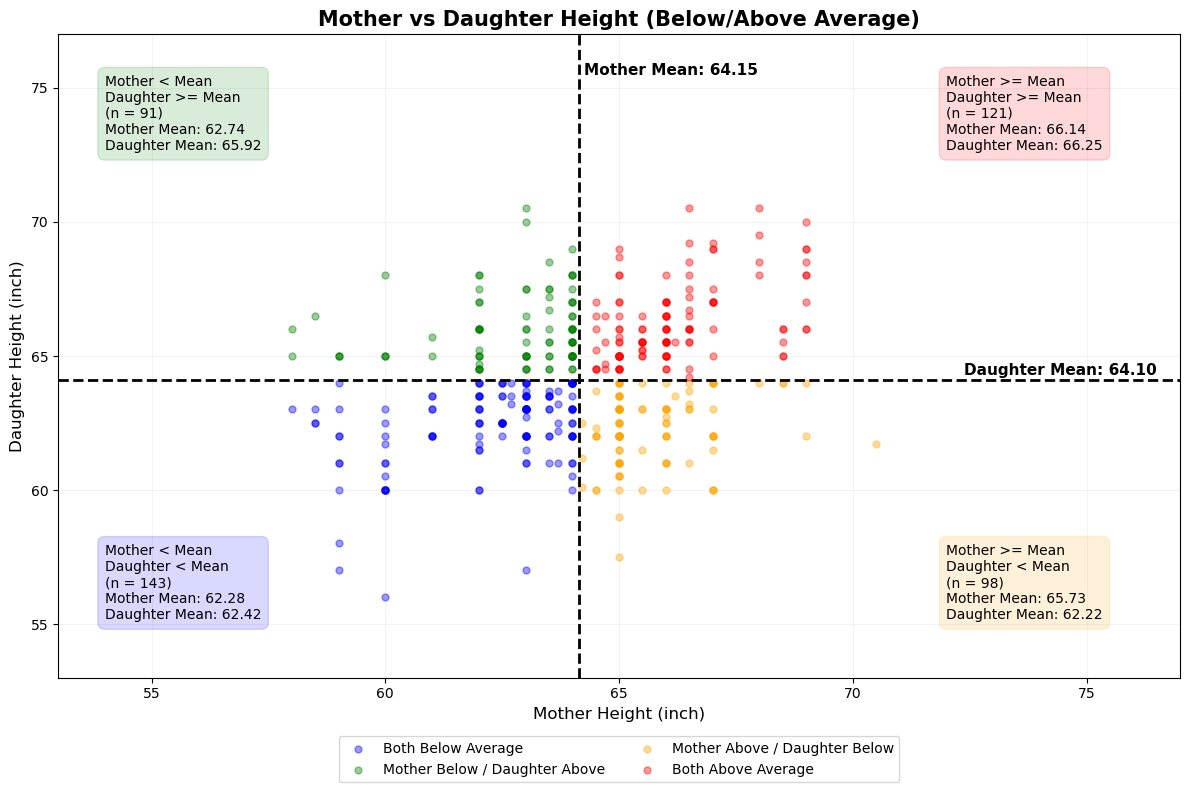

엄마 전체 평균 키: 64.15 inch
딸 전체 평균 키: 64.10 inch


In [82]:
#(4) 아버지, 엄마의 키를 알면 아들키를 추정하는 회귀식을 구하시오.

Y = maleData['childHeight'].to_numpy()
X = maleData[['father', 'mother']].to_numpy()

linreg = linear_model.LinearRegression()
model = linreg.fit(X, Y)
coef4 = model.coef_
intercept4 = model.intercept_
print(f"(4) 아들 키 회귀식: Y = {coef4[0]:.4f}X1 + {coef4[1]:.4f}X2 + {intercept4:.4f}")

# 예상값 출력
father_height = float(input("아빠 키를 입력하세요: "))
mother_height = float(input("엄마 키를 입력하세요: "))
son_height = coef4[0] * father_height + coef4[1] * mother_height + intercept4

print(f"입력한 아빠의 키: {father_height}")
print(f"입력한 엄마의 키: {mother_height}")
print(f"예측한 아들의 키: {son_height:.2f}")

(4) 아들 키 회귀식: Y = 0.4176X1 + 0.3288X2 + 19.3128
입력한 아빠의 키: 70.0
입력한 엄마의 키: 60.0
예측한 아들의 키: 68.27


In [84]:
# (5) 아버지, 엄마의 키를 알면 딸 키를 추정하는 회귀식을 구하시오.

Y = femaleData['childHeight'].to_numpy()
X = femaleData[['father', 'mother']].to_numpy()

linreg = linear_model.LinearRegression()
model = linreg.fit(X, Y)
coef5 = model.coef_
intercept5 = model.intercept_

print(f"딸 키 회귀식: Y = {coef5[0]:.4f}X1 + {coef5[1]:.4f}X2 + {intercept5:.4f}")

# 예상값 출력
father_height = float(input("아빠 키를 입력하세요: "))
mother_height = float(input("엄마 키를 입력하세요: "))

daughter_height = coef5[0] * father_height + coef5[1] * mother_height + intercept5

print(f"입력한 아빠의 키: {father_height}")
print(f"입력한 엄마의 키: {mother_height}")
print(f"예측한 딸의 키: {daughter_height:.2f}")

딸 키 회귀식: Y = 0.3725X1 + 0.3035X2 + 18.8336
입력한 아빠의 키: 70.0
입력한 엄마의 키: 60.0
예측한 딸의 키: 63.12
